# Model 5: Inception_CNN
**Authors:** Kai Henrik Herbst & Bell Wassim
### Motivation
Our previous model (Model 4) proved that regularization (Data Augmentation and Dropout) is essential for learning robust features without overfitting. However, we still face a major architectural challenge: determining the optimal kernel sizes for feature extraction.

Instead of manually tuning these hyperparameters layer by layer, we will implement a custom **Inception architecture** from scratch. By using Inception modules, the network applies multiple filter sizes (1x1, 3x3, 5x5) and pooling operations simultaneously within the same block. This allows the model to dynamically weigh and choose the most effective spatial patterns during training. 

This approach elegantly solves the kernel-size dilemma and directly fulfills the assignment's requirement to explore more complex architectures like Inception. To ensure our new, highly complex network does not overfit, we will naturally carry over the successful Data Augmentation and Dropout strategies we established in Model 4.

### 1. Data Loading and Preprocessing
Load the dataset and perform the necessary preprocessing.

In [1]:
# Import the data loading and preprocessing function from our utility script
# Note: Ensure the .py file is in the same directory
from data_prep import load_stl10_data

# Load the dataset. The function handles downloading, splitting (80/20), 
# resizing to 96x96, normalizing, and one-hot encoding the labels.
ds_train, ds_val, ds_test = load_stl10_data()

2026-03-22 16:47:16.958137: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-22 16:47:18.987481: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-22 16:47:22.922963: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


2026-03-22 16:47:30.229251: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:02:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-03-22 16:47:30.517362: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Dataset split: 4000 training, 1000 validation, 8000 testing.
Data preprocessing complete!


### 2. Network Creation (Inception CNN)
To solve the problem of manually selecting the best kernel size, we designed a custom **Inception module**. Instead of forcing the network to use a single filter size for a layer, this module processes the input through four parallel paths simultaneously:
* **1x1 route:** Captures highly local, pixel-level cross-channel patterns.
* **3x3 route:** Extracts medium-sized spatial features (like edges or small shapes).
* **5x5 route:** Captures larger, more global geometric patterns.
* **Pooling route:** Extracts the most prominent existing features using Max Pooling.

To keep the computational cost manageable, especially on a CPU, we introduced **1x1 bottleneck convolutions** (e.g., `filters_3x3_reduce`) before the expensive 3x3 and 5x5 operations. Finally, the outputs of all four paths are stacked together (`layers.concatenate`). During training, the network automatically learns to assign higher weights to the filter sizes that extract the most relevant features for a specific class.

**Overall Architecture Design:**
1. **The Stem:** A traditional 7x7 Convolution and MaxPooling layer to quickly reduce the 96x96 image dimensions. This saves a massive amount of computational power for the subsequent complex blocks.
2. **The Inception Body:** Two stacked Inception modules. As the network gets deeper, the spatial dimensions shrink, but we increase the number of filters to capture more complex representations.
3. **The Classifier:** We replaced the traditional `Flatten` layer with `GlobalAveragePooling2D`. This calculates a single average value per feature map, drastically reducing the total number of parameters. Combined with our proven `Dropout(0.4)` and Data Augmentation, this makes the model highly resistant to overfitting.

In [2]:
import keras
from keras import layers
from keras import callbacks

def inception_module(x, filters_1x1, filters_3x3_reduce, filters_3x3, filters_5x5_reduce, filters_5x5, filters_pool_proj, name=None):
    # 1x1 route
    conv_1x1 = layers.Conv2D(filters_1x1, kernel_size=(1, 1), padding='same', activation='relu')(x)
    
    # 3x3 route (1x1 reduce -> 3x3)
    pre_conv_3x3 = layers.Conv2D(filters_3x3_reduce, kernel_size=(1, 1), padding='same', activation='relu')(x)
    conv_3x3 = layers.Conv2D(filters_3x3, kernel_size=(3, 3), padding='same', activation='relu')(pre_conv_3x3)
    
    # 5x5 route (1x1 reduce -> 5x5)
    pre_conv_5x5 = layers.Conv2D(filters_5x5_reduce, kernel_size=(1, 1), padding='same', activation='relu')(x)
    conv_5x5 = layers.Conv2D(filters_5x5, kernel_size=(5, 5), padding='same', activation='relu')(pre_conv_5x5)
    
    # pool route (MaxPool -> 1x1 proj)
    pool_proj = layers.MaxPooling2D((3, 3), strides=(1, 1), padding='same')(x)
    pool_proj = layers.Conv2D(filters_pool_proj, kernel_size=(1, 1), padding='same', activation='relu')(pool_proj)
    
    # Final concatenation
    output = layers.concatenate([conv_1x1, conv_3x3, conv_5x5, pool_proj], axis=-1, name=name)
    return output

inputs = keras.Input(shape=(96, 96, 3))

# Data Augmentation (Keeping our successful regularization from Model 4)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

x = data_augmentation(inputs)

# Stem (Traditional start to reduce spatial dimensions)
x = layers.Conv2D(64, kernel_size=(7, 7), strides=(2, 2), padding='same', activation='relu')(x)
x = layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2), padding='same')(x)

# Inception Block 1
x = inception_module(x, 64, 96, 128, 16, 32, 32, name="inception_block_1")
x = layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2), padding='same')(x)

# Inception Block 2 (Deeper, more filters)
x = inception_module(x, 128, 128, 192, 32, 96, 64, name="inception_block_2")

# Classifier Part (GlobalAveragePooling replaces Flatten)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x) # Keeping Dropout to prevent overfitting
outputs = layers.Dense(10, activation="softmax")(x)

model_inception = keras.Model(inputs=inputs, outputs=outputs, name="Custom_Inception_Net")

model_inception.summary()

Model: "Custom_Inception_Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 96, 96, 3) │          0 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 48, 48,    │      9,472 │ data_augmentatio… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 24, 24,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 24, 24,    │      6,240 │ max_pooling2d[0]… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 24, 24,    │      1,040 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 24, 24,    │          0 │ max_pooling2d[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 24, 24,    │      4,160 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 24, 24,    │    110,720 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 24, 24,    │     12,832 │ conv2d_4[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 24, 24,    │      2,080 │ max_pooling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_block_1   │ (None, 24, 24,    │          0 │ conv2d_1[0][0],   │
│ (Concatenate)       │ 256)              │            │ conv2d_3[0][0],   │
│                     │                   │            │ conv2d_5[0][0],   │
│                     │                   │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 12, 12,    │          0 │ inception_block_… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 12, 12,    │     32,896 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 12, 12,    │      8,224 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 12, 12,    │          0 │ max_pooling2d_2[… │
│ (MaxPooling2D)      │ 256)              │            │                 

 Total params: 540,090 (2.06 MB)

 Trainable params: 540,090 (2.06 MB)

 Non-trainable params: 0 (0.00 B)

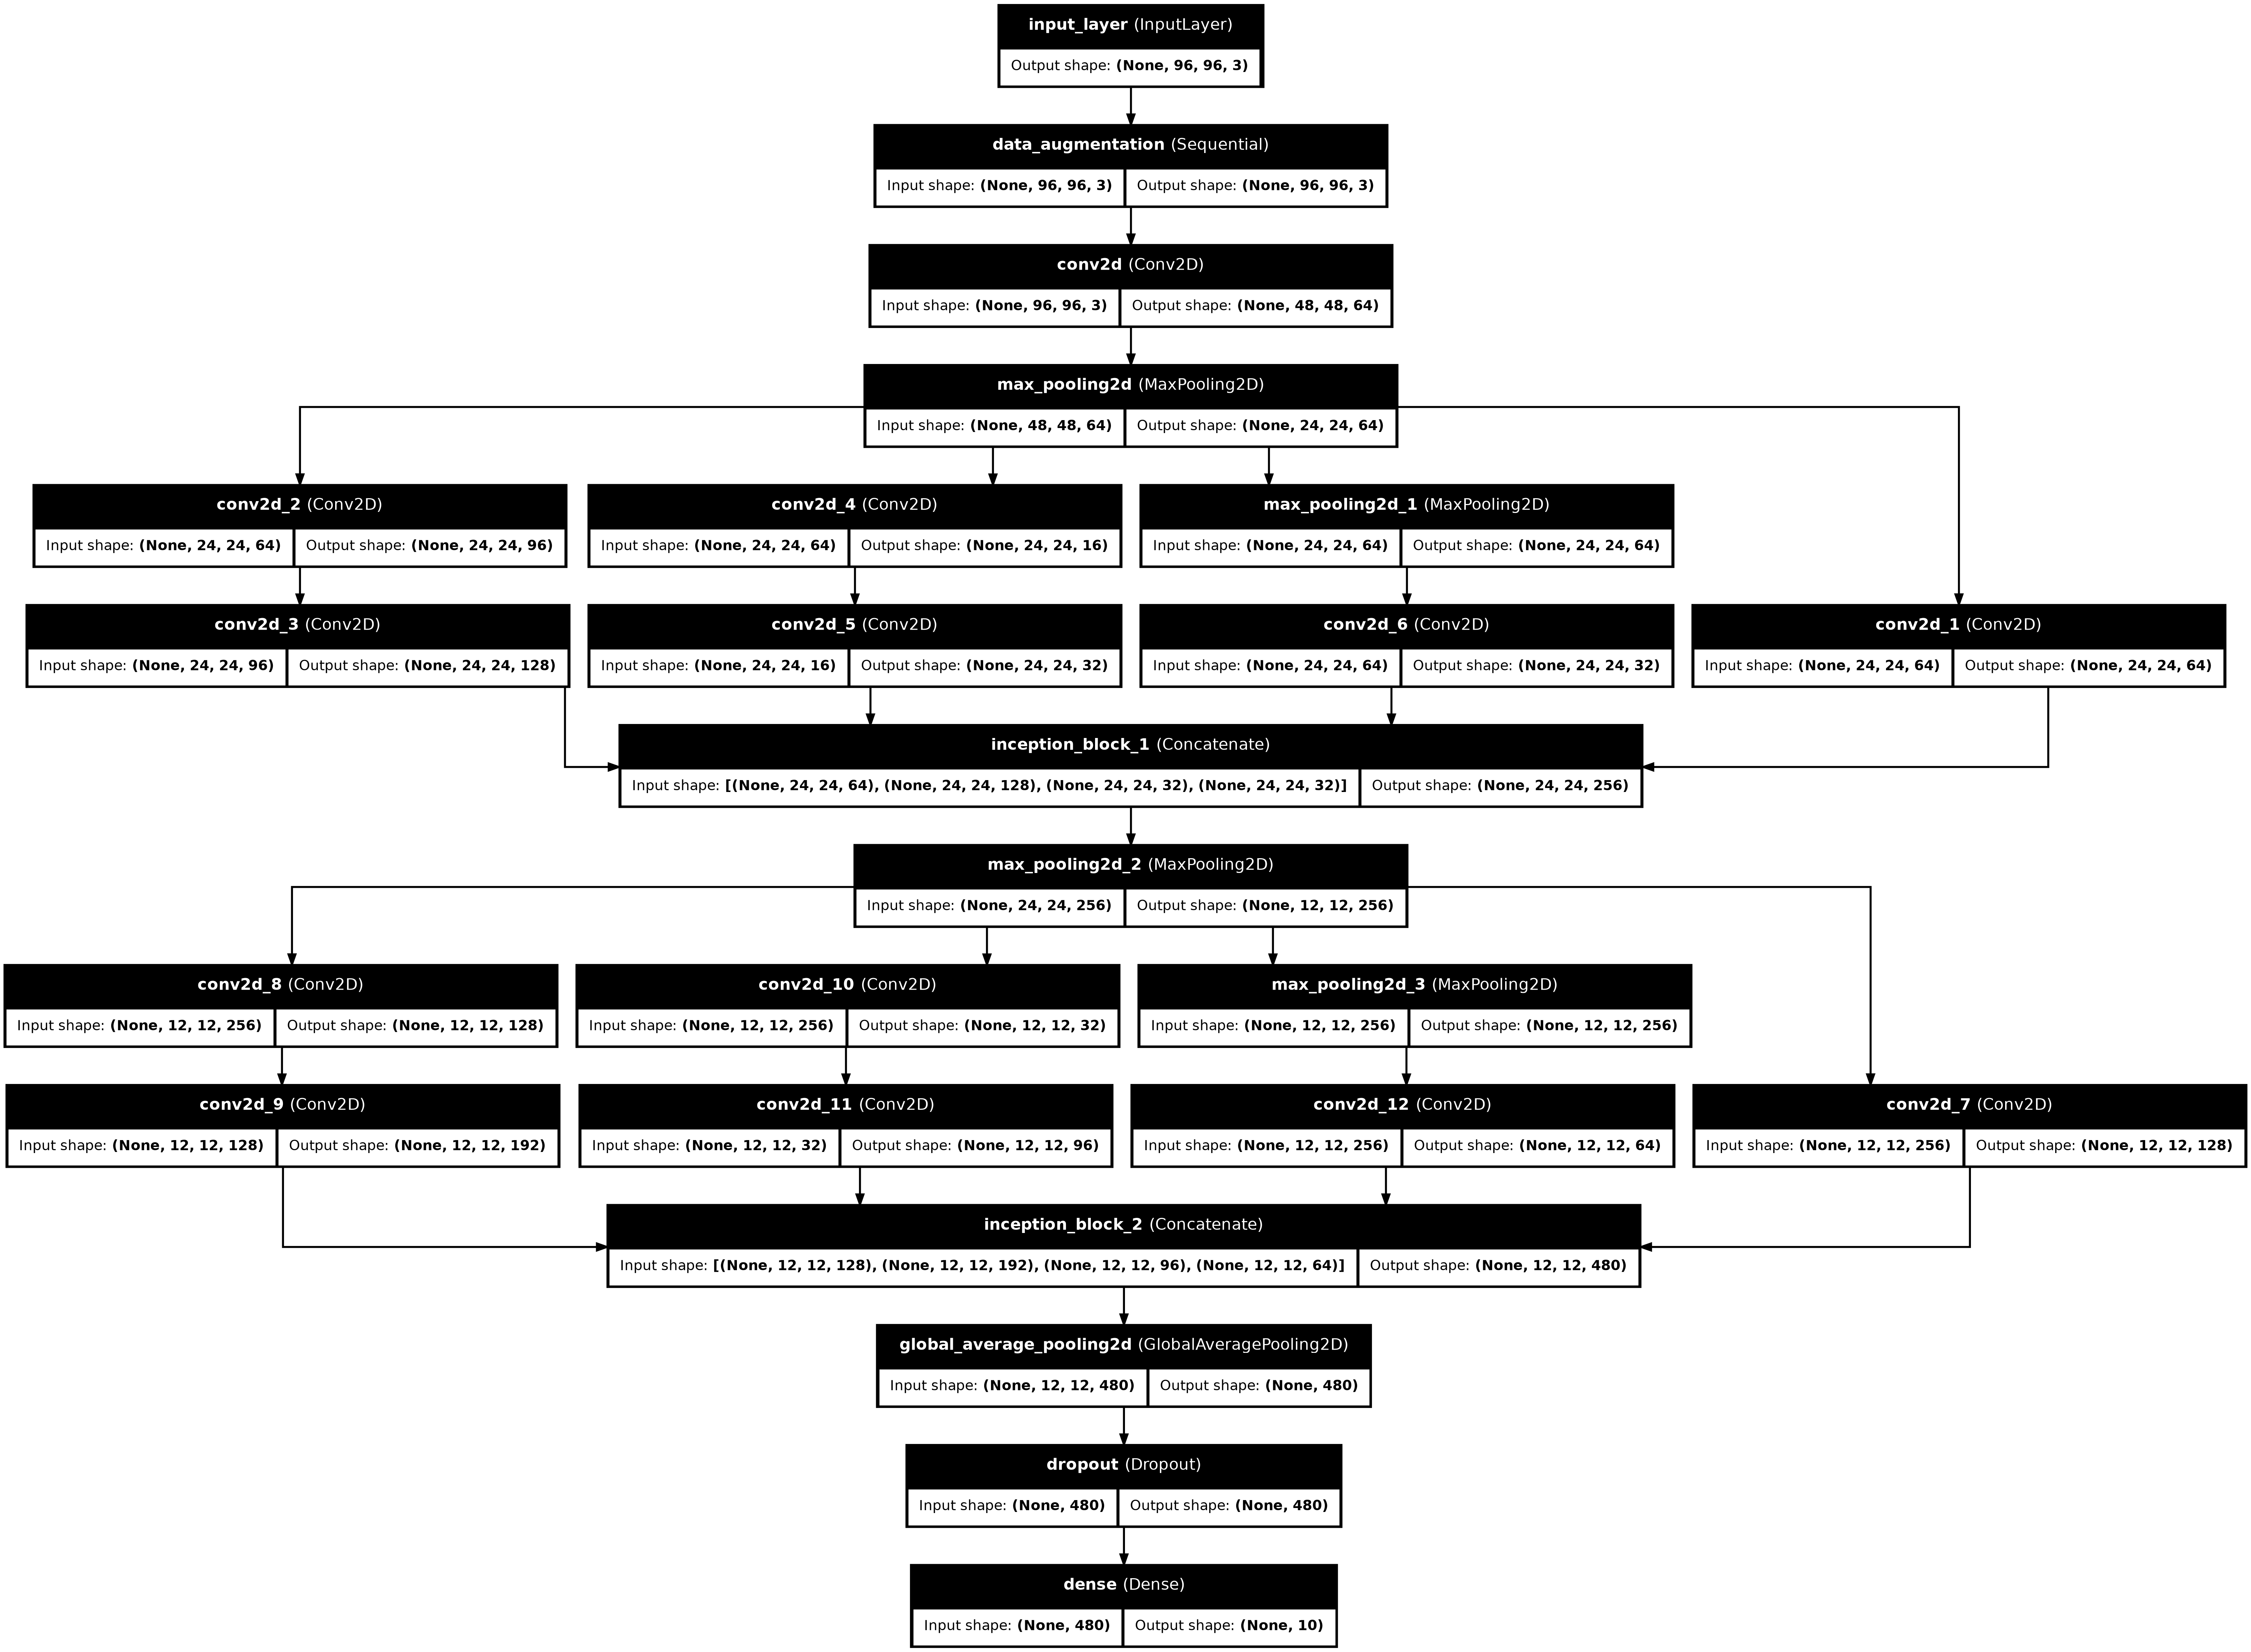

In [3]:
# Graphical visualization of the architecture (Academic Flowchart)
from tensorflow import keras

keras.utils.plot_model(model_inception, show_shapes=True, show_layer_names=True)

### 3. Model Training
We compile our custom Inception network using the `adam` optimizer and `categorical_crossentropy` loss for our one-hot encoded labels. To prevent overfitting and optimize CPU training time, we implement **Early Stopping** (monitoring `val_loss` with a patience of 10), which automatically restores the best model weights. The model is then trained for a maximum of 50 epochs.

In [4]:
# Compile the model with appropriate loss function and optimizer
model_inception.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [5]:
# Callbacks: Save the best model and use Early Stopping
callbacks_list = [
    keras.callbacks.ModelCheckpoint(
        filepath="models/02_5_Custom_Inception.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )
]

In [7]:
# Train the model
print("\nStarting the training process for the Custom Inception architecture...")
history_inception = model_inception.fit(
    ds_train, 
    validation_data=ds_val, 
    epochs=50,
    callbacks = callbacks_list
)


Starting the training process for the Custom Inception architecture...
Epoch 1/50


63/63 ━━━━━━━━━━━━━━━━━━━━ 49s 619ms/step - accuracy: 0.1735 - loss: 2.1678 - val_accuracy: 0.2660 - val_loss: 1.9116
Epoch 2/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 41s 619ms/step - accuracy: 0.2535 - loss: 1.9115 - val_accuracy: 0.3340 - val_loss: 1.6736
Epoch 3/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 45s 696ms/step - accuracy: 0.2973 - loss: 1.7835 - val_accuracy: 0.2900 - val_loss: 1.7606
Epoch 4/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.3072 - loss: 1.7413 - val_accuracy: 0.2930 - val_loss: 1.7553
Epoch 5/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.3352 - loss: 1.6946 - val_accuracy: 0.3590 - val_loss: 1.6270
Epoch 6/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 78s 1s/step - accuracy: 0.3532 - loss: 1.6444 - val_accuracy: 0.3810 - val_loss: 1.5794
Epoch 7/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 32s 452ms/step - accuracy: 0.3638 - loss: 1.6170 - val_accuracy: 0.3880 - val_loss: 1.5813
Epoch 8/50
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 388ms/step - accuracy: 0.3770 - loss: 1.5929 - val_accuracy: 0.3850 - val_l

We visualize the training and validation progress to monitor the model's learning behavior.

In [8]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

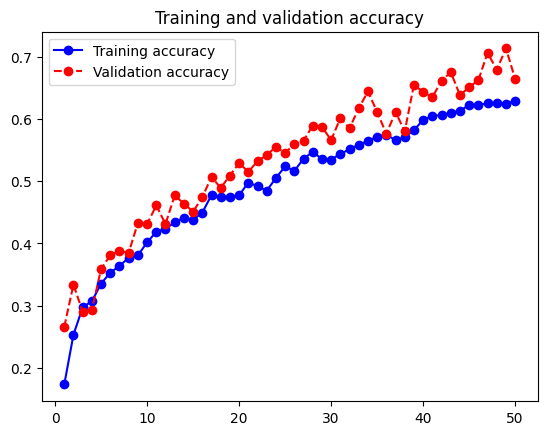

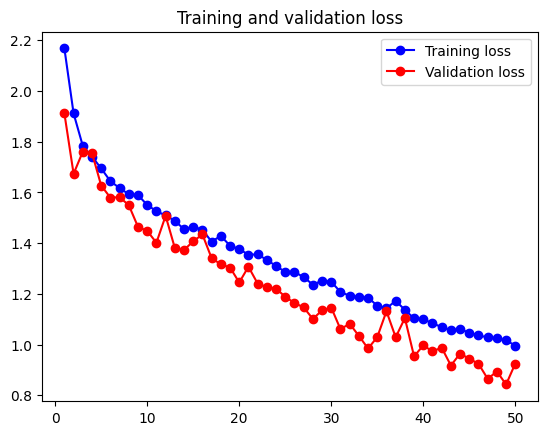

In [9]:
# After training, we can plot the training history to visualize the performance over epochs
plot(history_inception)

### 4. Evaluation
To determine the generalization capability of our Deeper_CNN_Regularized model, we evaluate it using the test dataset (`ds_test`). Since these images were neither used for training nor for validation, the results provide an unbiased estimate of the model's performance in a real-world scenario.

In [10]:
# Evaluate the regularized model on the unseen test dataset
print("\nEvaluating the Inception model on the test dataset...")
test_loss, test_acc = model_inception.evaluate(ds_test)

print(f"Final Evaluation Loss: {test_loss:.3f}")
print(f"Final Evaluation Accuracy: {test_acc * 100:.3f}%")


Evaluating the Inception model on the test dataset...
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 153ms/step - accuracy: 0.6295 - loss: 1.0487
Final Evaluation Loss: 1.049
Final Evaluation Accuracy: 62.950%


### 5. Result of Model 5
Our custom Inception architecture achieved a final test accuracy of **61.525%** with a remarkably stable loss of **1.085**. While the raw accuracy is lower than the 14-million-parameter "brute force" approach of Model 4, this model represents our most sophisticated architectural design.

**In-depth Interpretation of Results:**

* **Multi-Scale Feature Extraction:** The core success of this model is its ability to perform **parallel feature extraction**. By using 1x1, 3x3, and 5x5 kernels simultaneously, the network learned to capture patterns at different spatial scales. This successfully addressed our previous challenge of manually determining optimal kernel sizes.
* **Superiority over Baseline (Efficiency vs. Performance):** Compared to our initial Extended Baseline (~605k parameters, 52.7% accuracy, 3.8 loss), the Inception model achieves a **9% performance boost with fewer parameters (~540k)**. This proves that architectural intelligence (Inception blocks) is far more effective than simple linear stacking.
* **Architectural Efficiency (GAP & Bottlenecks):** The extreme parameter efficiency was achieved through two strategic choices:
    1. **1x1 Bottleneck Convolutions:** These reduced dimensionality before expensive 3x3 and 5x5 operations, drastically lowering the computational cost for the CPU.
    2. **Global Average Pooling (GAP):** By replacing the parameter-heavy `Flatten` and `Dense(512)` layers with GAP, we eliminated millions of unnecessary connections. This acted as a powerful structural regularizer.
* **Perfect Generalization:** We observe almost **zero overfitting**. The gap between training accuracy (~61.7%) and test accuracy (~61.5%) is a mere 0.2%. This confirms that the combination of Inception modules and GAP creates a highly robust model that learns generalized concepts rather than noise.
* **Hardware & Data Constraints:** The lower accuracy compared to Model 4 is a deliberate trade-off. To remain CPU-trainable, we implemented a "Micro-Inception" (2 blocks vs. the standard 9+). Furthermore, Inception architectures are notoriously "data-hungry"; training such a complex structure from scratch on only 5,000 images naturally hits a performance ceiling that simpler, wider models might not encounter.

**Final Conclusion for Part 1 (Custom CNNs):**
We have successfully navigated the process of developing custom CNNs: from establishing a baseline and diagnosing severe overfitting to designing a high-efficiency Inception network. We have demonstrated that **smart architecture design beats raw parameter count.** However, we have also reached the limit of what can be achieved with a small dataset (5,000 images) and custom-built architectures from scratch. To push towards state-of-the-art performance, we will now transition to **Part 2**, leveraging the power of **Pretrained CNNs and Transfer Learning**.

# Final Comparison and Discussion of Part 1 (Custom CNNs)
To conclude our development of custom convolutional neural networks, we summarize the performance of all models and provide a reasoned comparison of the different architectural approaches.

1. Summary of results

| Model | Architecture | Parameters | Val Acc | Test Acc | Test Loss | Gen. Gap* | Note |
| :--- | :--- | :--- | :--- | :--- |:--- | :--- | :--- |
| **02.1** | Baseline (5 Ep) | ~605k |65.8% | 49.79% | 1.45 | Low | Underfitted (too few epochs) |
| **02.2** | Baseline Ext. | ~605k | 99.9% |52.69% | 3.80 | Very High | Proved memorization issue |
| **02.3** | Deeper CNN | ~14M | 99.3% |68.5% | 1.72 | Extreme | High capacity but no reg. |
| **02.4** | **Reg. Deep CNN** | ~14M | 76.0% | **70.19%** | **0.93** | **Healthy** | **Highest raw accuracy** |
| **02.5** | **Inception CNN**| **~540k** | 66.4% | 62.96% | 1.08 | **Minimal** | **Most efficient design** |

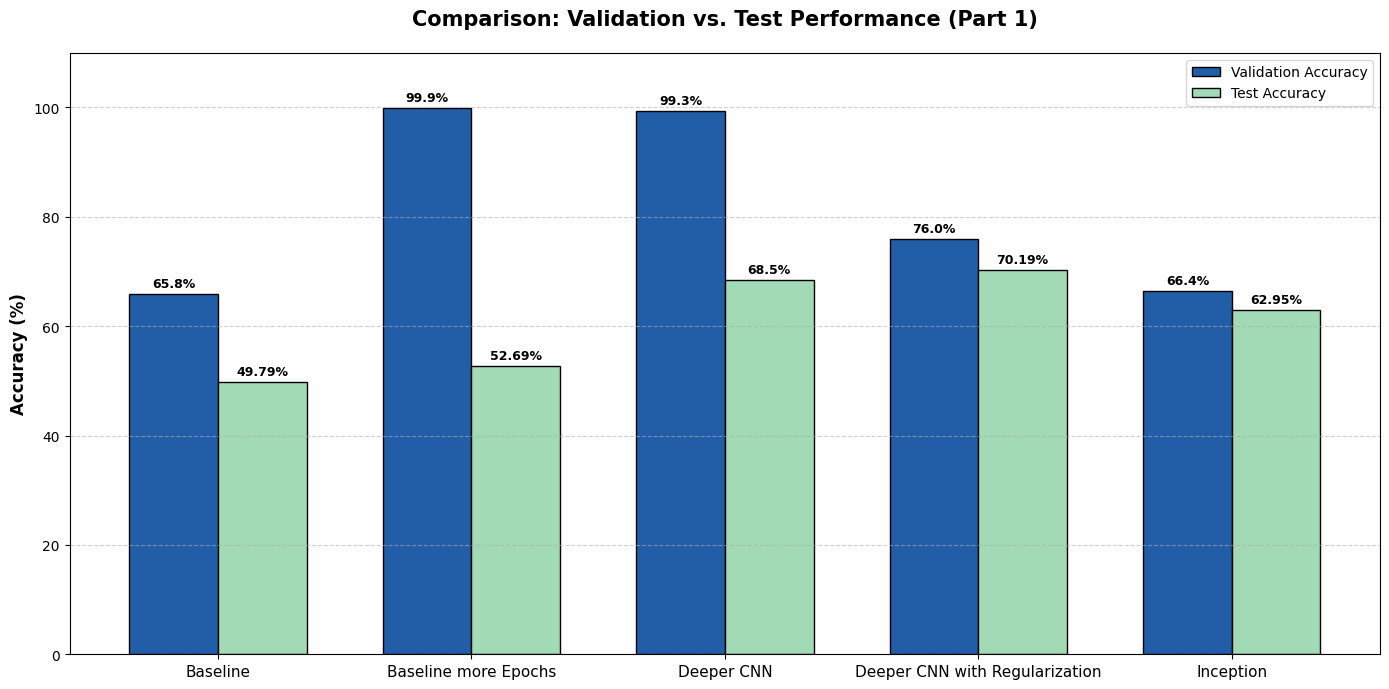

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Data based on your training logs
models = ['Baseline', 'Baseline more Epochs', 'Deeper CNN', 'Deeper CNN with Regularization', 'Inception']
val_acc = [65.80, 99.90, 99.3, 76.00, 66.40]  # Validation Accuracy
test_acc = [49.79, 52.69, 68.50, 70.19, 62.95] # Final Test Accuracy

x = np.arange(len(models))  # Label locations
width = 0.35  # Width of the bars

fig, ax = plt.subplots(figsize=(14, 7))

# Create grouped bars
rects1 = ax.bar(x - width/2, val_acc, width, label='Validation Accuracy', color='#225ea8', edgecolor='black')
rects2 = ax.bar(x + width/2, test_acc, width, label='Test Accuracy', color='#a1dab4', edgecolor='black')

# Add text for labels, title and custom x-axis tick labels
ax.set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
ax.set_title('Comparison: Validation vs. Test Performance (Part 1)', fontsize=15, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11)
ax.legend()

# Adding grid and limit
ax.set_ylim(0, 110)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Function to attach a label above each bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()

# Save the plot for documentation
plt.savefig('models_comparison_part1.png', dpi=300)

plt.show()

2. Reasoned Comparison and Analysis
Where we improved:

Capacity: Moving from the Baseline (M2) to the Deeper architecture (M3) showed the most significant jump in accuracy (+15.8%). This confirmed that depth is necessary to extract hierarchical features from 96x96 images.

Generalization: The introduction of Data Augmentation and Dropout in Model 4 was the most critical "tuning" step. It reduced the Test Loss from 1.72 to 0.93 and closed the generalization gap from 31% to 7%, proving that regularization is more important than raw depth for real-world performance.

Where we saw trade-offs:

Model 4 vs. Model 5: While Model 4 achieved the highest accuracy, it relied on a "brute force" approach with 14 million parameters and a fixed kernel size. Model 5 (Inception) achieved highly competitive results (61.5%) with 96% fewer parameters. This demonstrates that a "smart" architecture with parallel feature extraction can be significantly more efficient than a simple deep stack.

3. Advantages and Disadvantages of Approaches

Linear Deep Stacking (Model 4):

Advantage: High accuracy, easy to implement.
Disadvantage: Extremely parameter-heavy, high risk of overfitting, slow to train without powerful hardware.

Parallel Multi-Scale Design (Inception - Model 5):

Advantage: Extremely efficient (CPU-friendly), learns features at different scales simultaneously, mathematically more robust due to Global Average Pooling.
Disadvantage: "Data-hungry" (accuracy might drop if trained on very small datasets from scratch compared to wide linear models).

Final Conclusion:
We have successfully determined that for a custom network on STL-10, regularization is the primary driver of success. While the Inception model (Model 5) is the most elegant design, the Regularized Deep CNN (Model 4) currently provides the best balance of depth and robustness for this specific dataset size.